In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

DATA_DIR = Path(
    r"D:\MASTERS\FOML\assignment\202618026_AumTailor_DS605\202618026_lab_07\Data"
)

IMAGE_SIZE = (100, 100)
RANDOM_STATE = 42

print("Dataset directory exists:", DATA_DIR.exists())
print("Dataset directory:", DATA_DIR)

Dataset directory exists: True
Dataset directory: D:\MASTERS\FOML\assignment\202618026_AumTailor_DS605\202618026_lab_07\Data


In [2]:
X = []
y = []

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".pgm"}

for subject_dir in sorted(DATA_DIR.iterdir()):
    if not subject_dir.is_dir():
        continue

    subject_label = subject_dir.name

    for image_path in sorted(subject_dir.iterdir()):
        if image_path.suffix.lower() not in valid_extensions:
            continue

        try:
            with Image.open(image_path) as image:
                image = image.convert("L")
                image = image.resize(IMAGE_SIZE)

                image_array = np.asarray(image, dtype=np.float64)
                image_vector = image_array.flatten()

                X.append(image_vector)
                y.append(subject_label)

        except (OSError, ValueError) as error:
            print(f"Skipping {image_path.name}: {error}")

X = np.asarray(X, dtype=np.float64)
y = np.asarray(y)

print("Dataset loaded successfully")
print("Number of images:", len(X))
print("Number of subjects:", len(np.unique(y)))
print("Feature matrix shape:", X.shape)
print("Label array shape:", y.shape)
print("Image dimensions:", IMAGE_SIZE)

Dataset loaded successfully
Number of images: 400
Number of subjects: 40
Feature matrix shape: (400, 10000)
Label array shape: (400,)
Image dimensions: (100, 100)


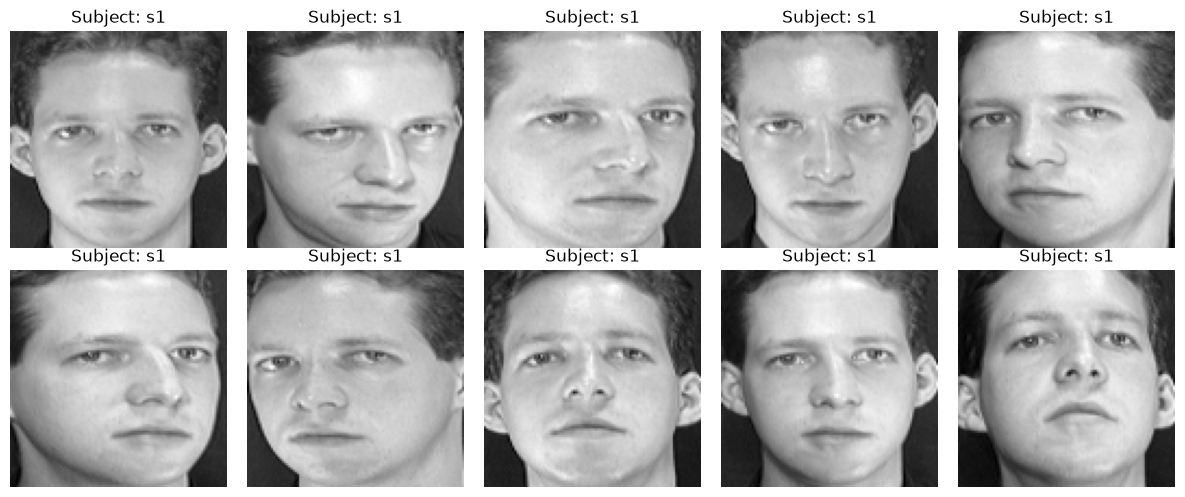

Saved: D:\MASTERS\FOML\assignment\202618026_AumTailor_DS605\202618026_lab_07\output\sample_faces.png


In [4]:
OUTPUT_DIR = DATA_DIR.parent / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(IMAGE_SIZE), cmap="gray")
    ax.set_title(f"Subject: {y[i]}")
    ax.axis("off")

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "sample_faces.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Saved:", OUTPUT_DIR / "sample_faces.png")

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Test images:", X_test.shape[0])
print("Features per image:", X_train.shape[1])
print("Training subjects:", len(np.unique(y_train)))
print("Test subjects:", len(np.unique(y_test)))

print("\nTraining images per subject:")
print(np.unique(y_train, return_counts=True)[1][:5])

print("\nTest images per subject:")
print(np.unique(y_test, return_counts=True)[1][:5])

Training images: 320
Test images: 80
Features per image: 10000
Training subjects: 40
Test subjects: 40

Training images per subject:
[8 8 8 8 8]

Test images per subject:
[2 2 2 2 2]


## B1. Mean Face Calculation

Mean face vector shape: (10000,)
Mean face image shape: (100, 100)
Minimum mean pixel value: 59.25625
Maximum mean pixel value: 171.4


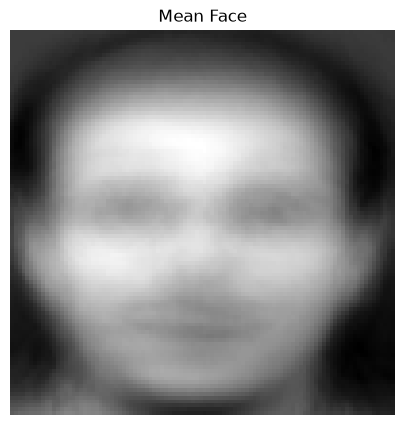

In [6]:
# Calculate the mean pixel value at each position
mean_face = np.mean(X_train, axis=0)

# Reshape the mean vector into a 100 x 100 image
mean_face_image = mean_face.reshape(IMAGE_SIZE)

print("Mean face vector shape:", mean_face.shape)
print("Mean face image shape:", mean_face_image.shape)
print("Minimum mean pixel value:", mean_face.min())
print("Maximum mean pixel value:", mean_face.max())

plt.figure(figsize=(5, 5))
plt.imshow(mean_face_image, cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.show()

## B2. Mean Centering

In [7]:
# Center the training data using the training mean face
X_train_centered = X_train - mean_face

print("Centered training matrix shape:", X_train_centered.shape)
print("Mean of centered data:", np.mean(X_train_centered))
print("Mean of each pixel after centering (first 5):")
print(np.mean(X_train_centered, axis=0)[:5])

Centered training matrix shape: (320, 10000)
Mean of centered data: -1.0913936421275139e-16
Mean of each pixel after centering (first 5):
[5.46229728e-15 7.01660952e-15 5.81756865e-15 6.57252031e-15
 0.00000000e+00]


## B3. Compute the Covariance Matrix

In [8]:
# Compute the smaller Gram matrix
gram_matrix = X_train_centered @ X_train_centered.T

print("Gram matrix shape:", gram_matrix.shape)
print("Is the matrix symmetric:", np.allclose(gram_matrix, gram_matrix.T))
print("Minimum diagonal value:", np.min(np.diag(gram_matrix)))
print("Maximum diagonal value:", np.max(np.diag(gram_matrix)))

Gram matrix shape: (320, 320)
Is the matrix symmetric: True
Minimum diagonal value: 7348067.189277342
Maximum diagonal value: 29897173.701777343


In [9]:
# Compute eigenvalues and eigenvectors of the Gram matrix
eigenvalues, eigenvectors = np.linalg.eigh(gram_matrix)

# Sort eigenvalues and eigenvectors in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

print("Eigenvalues shape:", eigenvalues.shape)
print("Eigenvectors shape:", eigenvectors.shape)
print("Largest eigenvalue:", eigenvalues[0])
print("Smallest eigenvalue:", eigenvalues[-1])
print("Number of negative eigenvalues:", np.sum(eigenvalues < 0))

Eigenvalues shape: (320,)
Eigenvectors shape: (320, 320)
Largest eigenvalue: 870691568.8539965
Smallest eigenvalue: -2.541122160452256e-09
Number of negative eigenvalues: 1


In [10]:
# Remove tiny negative eigenvalues caused by numerical precision
eigenvalues = np.maximum(eigenvalues, 0)

# Calculate explained variance ratios
total_variance = np.sum(eigenvalues)
explained_variance_ratio = eigenvalues / total_variance

# Calculate cumulative explained variance
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

# Find components required to retain 90% and 95% variance
components_90 = np.searchsorted(cumulative_explained_variance, 0.90) + 1
components_95 = np.searchsorted(cumulative_explained_variance, 0.95) + 1

print(f"Total variance: {total_variance:.2f}")
print(f"Components for 90% variance: {components_90}")
print(f"Components for 95% variance: {components_95}")
print(f"Variance retained by {components_90} components: "
      f"{cumulative_explained_variance[components_90 - 1]:.4f}")
print(f"Variance retained by {components_95} components: "
      f"{cumulative_explained_variance[components_95 - 1]:.4f}")

Total variance: 4899668385.43
Components for 90% variance: 91
Components for 95% variance: 153
Variance retained by 91 components: 0.9008
Variance retained by 153 components: 0.9503


## B6. Plot Cumulative Explained Variance

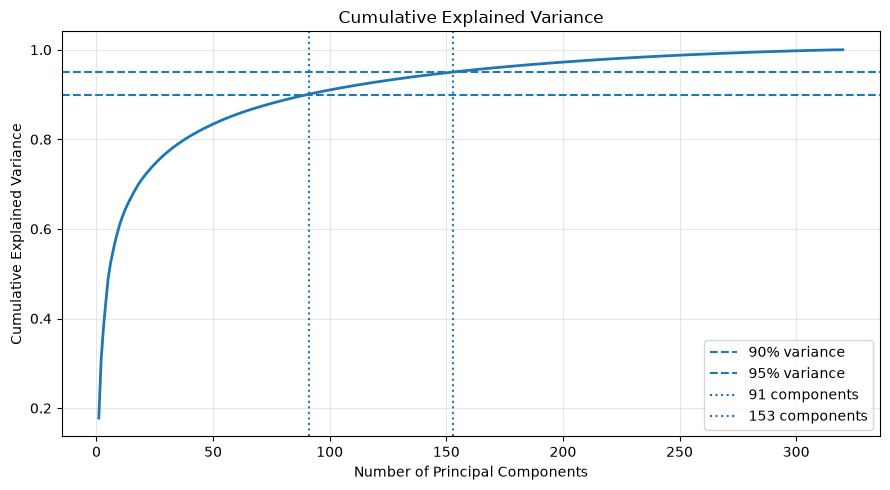

In [11]:
# Plot cumulative explained variance
fig, ax = plt.subplots(figsize=(9, 5))

components = np.arange(1, len(cumulative_explained_variance) + 1)

ax.plot(components, cumulative_explained_variance, linewidth=2)
ax.axhline(y=0.90, linestyle="--", label="90% variance")
ax.axhline(y=0.95, linestyle="--", label="95% variance")
ax.axvline(x=components_90, linestyle=":", label=f"{components_90} components")
ax.axvline(x=components_95, linestyle=":", label=f"{components_95} components")

ax.set_xlabel("Number of Principal Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.set_title("Cumulative Explained Variance")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "explained_variance.png", dpi=300, bbox_inches="tight")
plt.show()

## B7. Construct the Eigenfaces

In [12]:
# Keep only numerically meaningful eigenvalues
tolerance = eigenvalues[0] * 1e-12
valid_components = eigenvalues > tolerance

valid_eigenvalues = eigenvalues[valid_components]
valid_eigenvectors = eigenvectors[:, valid_components]

# Transform Gram-matrix eigenvectors into pixel-space eigenfaces
eigenfaces = (
    X_train_centered.T @ valid_eigenvectors
) / np.sqrt(valid_eigenvalues)

# Normalize eigenfaces
eigenfaces /= np.linalg.norm(eigenfaces, axis=0, keepdims=True)

print("Number of valid eigenfaces:", eigenfaces.shape[1])
print("Eigenfaces matrix shape:", eigenfaces.shape)
print("First five eigenface norms:",
      np.linalg.norm(eigenfaces[:, :5], axis=0))

Number of valid eigenfaces: 319
Eigenfaces matrix shape: (10000, 319)
First five eigenface norms: [1. 1. 1. 1. 1.]


## B8. Visualize the Mean Face and Eigenfaces

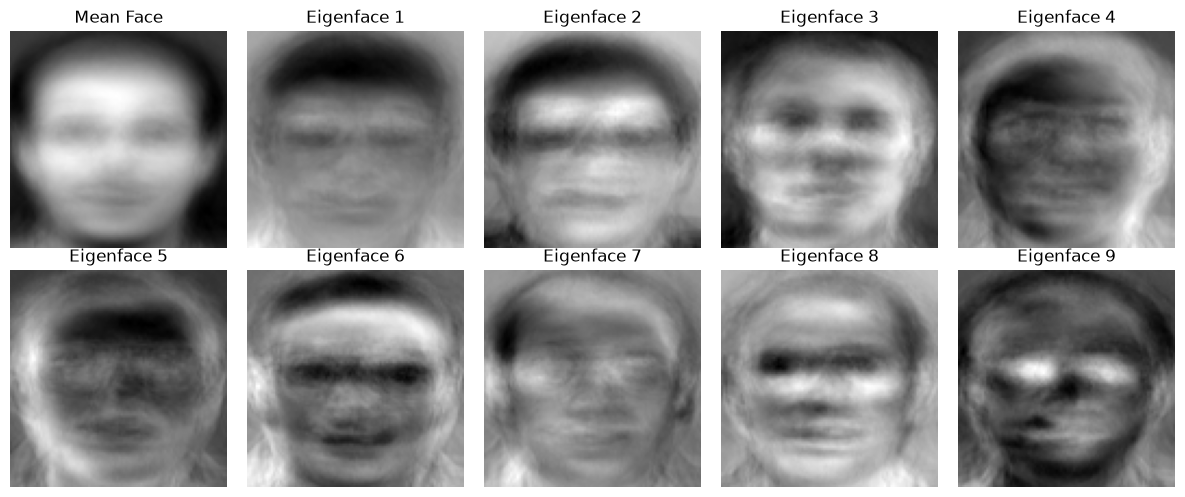

In [13]:
# Display the mean face and first 9 eigenfaces
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

axes[0, 0].imshow(mean_face.reshape(IMAGE_SIZE), cmap="gray")
axes[0, 0].set_title("Mean Face")
axes[0, 0].axis("off")

for i in range(9):
    row = (i + 1) // 5
    col = (i + 1) % 5

    eigenface_image = eigenfaces[:, i].reshape(IMAGE_SIZE)

    axes[row, col].imshow(eigenface_image, cmap="gray")
    axes[row, col].set_title(f"Eigenface {i + 1}")
    axes[row, col].axis("off")

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "eigenfaces.png", dpi=300, bbox_inches="tight")
plt.show()

## B9. Select Principal Components and Project Training Images

In [14]:
# Select the first 91 eigenfaces
K = components_90
eigenfaces_k = eigenfaces[:, :K]

# Project centered training images into PCA space
X_train_pca = X_train_centered @ eigenfaces_k

print("Number of selected components:", K)
print("Selected eigenfaces shape:", eigenfaces_k.shape)
print("Projected training data shape:", X_train_pca.shape)
print(f"Variance retained: {cumulative_explained_variance[K - 1]:.4f}")
print(f"Feature reduction: {(1 - K / X_train.shape[1]) * 100:.2f}%")

Number of selected components: 91
Selected eigenfaces shape: (10000, 91)
Projected training data shape: (320, 91)
Variance retained: 0.9008
Feature reduction: 99.09%


In [15]:
# Center test images using the training mean face
X_test_centered = X_test - mean_face

# Project test images into the same PCA space
X_test_pca = X_test_centered @ eigenfaces_k

print("Centered test data shape:", X_test_centered.shape)
print("Projected test data shape:", X_test_pca.shape)
print("Training PCA shape:", X_train_pca.shape)
print("Test PCA shape:", X_test_pca.shape)

Centered test data shape: (80, 10000)
Projected test data shape: (80, 91)
Training PCA shape: (320, 91)
Test PCA shape: (80, 91)


In [16]:
# Reconstruct test images from their PCA representations
X_test_reconstructed = X_test_pca @ eigenfaces_k.T + mean_face

print("Original test data shape:", X_test.shape)
print("Reconstructed test data shape:", X_test_reconstructed.shape)

# Calculate reconstruction errors
mse_per_image = np.mean(
    (X_test - X_test_reconstructed) ** 2, axis=1
)
overall_mse = np.mean(mse_per_image)
overall_rmse = np.sqrt(overall_mse)

print(f"Mean reconstruction MSE: {overall_mse:.4f}")
print(f"Overall reconstruction RMSE: {overall_rmse:.4f}")

Original test data shape: (80, 10000)
Reconstructed test data shape: (80, 10000)
Mean reconstruction MSE: 299.8171
Overall reconstruction RMSE: 17.3152


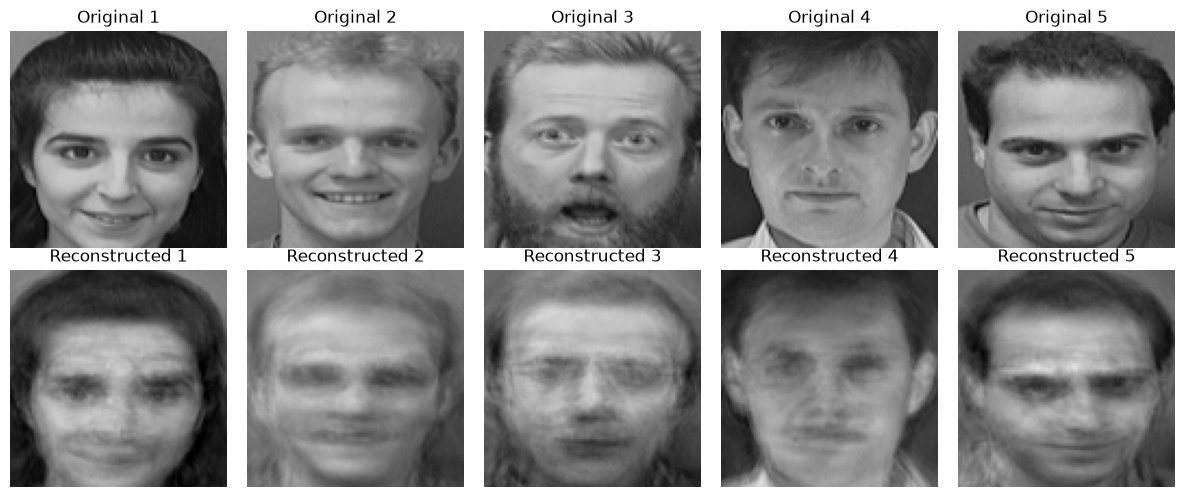

In [17]:
# Display five original and reconstructed test images
num_images = 5

fig, axes = plt.subplots(2, num_images, figsize=(12, 5))

for i in range(num_images):
    original = X_test[i].reshape(IMAGE_SIZE)
    reconstructed = X_test_reconstructed[i].reshape(IMAGE_SIZE)

    axes[0, i].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[0, i].set_title(f"Original {i + 1}")
    axes[0, i].axis("off")

    axes[1, i].imshow(
        np.clip(reconstructed, 0, 255),
        cmap="gray",
        vmin=0,
        vmax=255
    )
    axes[1, i].set_title(f"Reconstructed {i + 1}")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("Reconstructed", fontsize=11)

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "reconstruction_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## C3. Face Recognition Using Euclidean Distance

In [18]:
# Calculate distances between test and training images in PCA space
distance_matrix = np.sqrt(
    np.sum(
        (X_test_pca[:, np.newaxis, :] - X_train_pca[np.newaxis, :, :]) ** 2,
        axis=2
    )
)

# Find the nearest training image for each test image
nearest_indices = np.argmin(distance_matrix, axis=1)
y_pred_knn = y_train[nearest_indices]

# Evaluate recognition accuracy
accuracy = accuracy_score(y_test, y_pred_knn)

print(f"Nearest-neighbor recognition accuracy: {accuracy:.4f}")
print(f"Correct predictions: {np.sum(y_test == y_pred_knn)} / {len(y_test)}")
print("\nClassification report:")
print(classification_report(y_test, y_pred_knn, zero_division=0))

Nearest-neighbor recognition accuracy: 0.9875
Correct predictions: 79 / 80

Classification report:
              precision    recall  f1-score   support

          s1       1.00      1.00      1.00         2
         s10       1.00      1.00      1.00         2
         s11       1.00      1.00      1.00         2
         s12       1.00      1.00      1.00         2
         s13       1.00      1.00      1.00         2
         s14       1.00      1.00      1.00         2
         s15       1.00      1.00      1.00         2
         s16       1.00      1.00      1.00         2
         s17       1.00      1.00      1.00         2
         s18       1.00      1.00      1.00         2
         s19       1.00      1.00      1.00         2
          s2       1.00      1.00      1.00         2
         s20       1.00      1.00      1.00         2
         s21       1.00      1.00      1.00         2
         s22       1.00      1.00      1.00         2
         s23       1.00      1.00   

In [19]:
# Find indices of incorrect predictions
misclassified_indices = np.where(y_test != y_pred_knn)[0]

print("Number of misclassified images:", len(misclassified_indices))

for idx in misclassified_indices:
    print("Test image index:", idx)
    print("Actual subject:", y_test[idx])
    print("Predicted subject:", y_pred_knn[idx])
    print("Nearest training image index:", nearest_indices[idx])
    print("Nearest-neighbor distance:", distance_matrix[idx, nearest_indices[idx]])

Number of misclassified images: 1
Test image index: 9
Actual subject: s40
Predicted subject: s5
Nearest training image index: 16
Nearest-neighbor distance: 1968.8336367961335


## C5. Visualize the Misclassified Pair

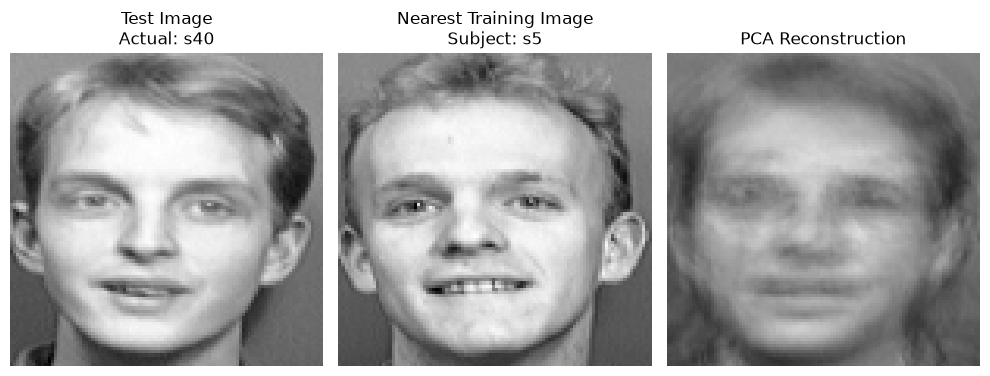

In [20]:
# Visualize the misclassified test image and its nearest training match
idx = misclassified_indices[0]
nearest_idx = nearest_indices[idx]

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

axes[0].imshow(X_test[idx].reshape(IMAGE_SIZE), cmap="gray")
axes[0].set_title(f"Test Image\nActual: {y_test[idx]}")
axes[0].axis("off")

axes[1].imshow(X_train[nearest_idx].reshape(IMAGE_SIZE), cmap="gray")
axes[1].set_title(f"Nearest Training Image\nSubject: {y_train[nearest_idx]}")
axes[1].axis("off")

axes[2].imshow(
    np.clip(X_test_reconstructed[idx].reshape(IMAGE_SIZE), 0, 255),
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[2].set_title("PCA Reconstruction")
axes[2].axis("off")

plt.tight_layout()
fig.savefig(
    OUTPUT_DIR / "recognition_examples.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## D1. Create a NumPy-Based PCA Transformer for Cross-Validation

In [21]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin


class NumPyEigenfacesPCA(BaseEstimator, TransformerMixin):
    def __init__(self, variance_threshold=0.90):
        self.variance_threshold = variance_threshold

    def fit(self, X, y=None):
        # Learn the mean face from this fold's training images
        self.mean_face_ = np.mean(X, axis=0)
        X_centered = X - self.mean_face_

        # Compute the smaller Gram matrix
        gram = X_centered @ X_centered.T

        # Eigenvalue decomposition using NumPy
        eigenvalues, eigenvectors = np.linalg.eigh(gram)

        # Sort in descending order
        order = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[order]
        eigenvectors = eigenvectors[:, order]

        # Remove numerical negatives
        eigenvalues = np.maximum(eigenvalues, 0)

        # Keep numerically meaningful components
        tolerance = eigenvalues[0] * 1e-12
        valid = eigenvalues > tolerance
        eigenvalues = eigenvalues[valid]
        eigenvectors = eigenvectors[:, valid]

        # Determine component count from this fold's training data
        ratios = eigenvalues / np.sum(eigenvalues)
        cumulative = np.cumsum(ratios)
        self.n_components_ = (
            np.searchsorted(cumulative, self.variance_threshold) + 1
        )

        eigenvalues = eigenvalues[:self.n_components_]
        eigenvectors = eigenvectors[:, :self.n_components_]

        # Convert Gram eigenvectors into pixel-space eigenfaces
        self.eigenfaces_ = (
            X_centered.T @ eigenvectors
        ) / np.sqrt(eigenvalues)

        # Normalize the eigenfaces
        self.eigenfaces_ /= np.linalg.norm(
            self.eigenfaces_, axis=0, keepdims=True
        )

        return self

    def transform(self, X):
        X_centered = X - self.mean_face_
        return X_centered @ self.eigenfaces_

In [22]:
pca_check = NumPyEigenfacesPCA(variance_threshold=0.90)
X_train_pca_check = pca_check.fit_transform(X_train)

print("Selected components:", pca_check.n_components_)
print("Transformed training shape:", X_train_pca_check.shape)
print("Eigenfaces shape:", pca_check.eigenfaces_.shape)

Selected components: 91
Transformed training shape: (320, 91)
Eigenfaces shape: (10000, 91)


## D2. Compare Traditional Classifiers Using Cross-Validation

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Define stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define classifiers with NumPy-based PCA preprocessing
models = {
    "KNN (k=1)": Pipeline([
        ("pca", NumPyEigenfacesPCA(variance_threshold=0.90)),
        ("classifier", KNeighborsClassifier(n_neighbors=1))
    ]),
    "Logistic Regression": Pipeline([
        ("pca", NumPyEigenfacesPCA(variance_threshold=0.90)),
        ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    ]),
    "SVM (RBF)": Pipeline([
        ("pca", NumPyEigenfacesPCA(variance_threshold=0.90)),
        ("classifier", SVC(kernel="rbf"))
    ])
}

# Evaluate models using only the training set
cv_results = {}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    cv_results[name] = scores

    print(f"{name}")
    print("Fold accuracies:", np.round(scores, 4))
    print(f"Mean CV accuracy: {scores.mean():.4f}")
    print(f"Standard deviation: {scores.std():.4f}")
    print()

KNN (k=1)
Fold accuracies: [1.     0.9531 0.9688 0.9375 0.9375]
Mean CV accuracy: 0.9594
Standard deviation: 0.0234

Logistic Regression
Fold accuracies: [1.     0.9531 0.9531 0.9688 0.9219]
Mean CV accuracy: 0.9594
Standard deviation: 0.0254

SVM (RBF)
Fold accuracies: [0.9844 0.9531 0.9531 0.9375 0.9375]
Mean CV accuracy: 0.9531
Standard deviation: 0.0171



## D3. Final Test Evaluation

In [24]:
# Fit the selected pipeline using the full training set
final_model = models["KNN (k=1)"]
final_model.fit(X_train, y_train)

# Predict identities for the untouched test set
y_test_pred_final = final_model.predict(X_test)

# Evaluate final test performance
test_accuracy = accuracy_score(y_test, y_test_pred_final)

print(f"Final test accuracy: {test_accuracy:.4f}")
print(f"Correct predictions: {np.sum(y_test == y_test_pred_final)} / {len(y_test)}")
print("\nClassification report:")
print(classification_report(y_test, y_test_pred_final, zero_division=0))

Final test accuracy: 0.9875
Correct predictions: 79 / 80

Classification report:
              precision    recall  f1-score   support

          s1       1.00      1.00      1.00         2
         s10       1.00      1.00      1.00         2
         s11       1.00      1.00      1.00         2
         s12       1.00      1.00      1.00         2
         s13       1.00      1.00      1.00         2
         s14       1.00      1.00      1.00         2
         s15       1.00      1.00      1.00         2
         s16       1.00      1.00      1.00         2
         s17       1.00      1.00      1.00         2
         s18       1.00      1.00      1.00         2
         s19       1.00      1.00      1.00         2
          s2       1.00      1.00      1.00         2
         s20       1.00      1.00      1.00         2
         s21       1.00      1.00      1.00         2
         s22       1.00      1.00      1.00         2
         s23       1.00      1.00      1.00         2


## D4. Summarize Model Comparison

In [27]:
import pandas as pd
from sklearn.metrics import accuracy_score

knn_cv_scores = cv_results["KNN (k=1)"]

# Use predictions from the final KNN model
knn_test_accuracy = accuracy_score(y_test, y_pred_knn)

knn_summary = pd.DataFrame([{
    "Model": "KNN (k=1)",
    "PCA Components": K,
    "Mean CV Accuracy": f"{knn_cv_scores.mean():.4f}",
    "CV Standard Deviation": f"{knn_cv_scores.std():.4f}",
    "Test Accuracy": f"{knn_test_accuracy:.4f}",
    "Correct Predictions": f"{int((y_test == y_pred_knn).sum())}/{len(y_test)}"
}])

print(knn_summary.to_string(index=False))

    Model  PCA Components Mean CV Accuracy CV Standard Deviation Test Accuracy Correct Predictions
KNN (k=1)              91           0.9594                0.0234        0.9875               79/80


In [28]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

knn_results = {}

for k in [1, 3, 5]:
    model = Pipeline([
        ("pca", NumPyEigenfacesPCA(variance_threshold=0.90)),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=1
    )

    knn_results[k] = scores

knn_comparison = pd.DataFrame([
    {
        "KNN": f"k={k}",
        "Mean CV Accuracy": f"{scores.mean():.4f}",
        "CV Standard Deviation": f"{scores.std():.4f}"
    }
    for k, scores in knn_results.items()
])

print(knn_comparison.to_string(index=False))

KNN Mean CV Accuracy CV Standard Deviation
k=1           0.9594                0.0234
k=3           0.9219                0.0221
k=5           0.8969                0.0364


In [29]:
# Inspect the original grayscale image matrix
sample_image = X[0].reshape(IMAGE_SIZE)

print("Image matrix shape:", sample_image.shape)
print("Image data type:", sample_image.dtype)
print("Minimum pixel intensity:", sample_image.min())
print("Maximum pixel intensity:", sample_image.max())
print("Mean pixel intensity:", sample_image.mean())

print("\nComplete dataset matrix shape:", X.shape)
print("Number of labels:", len(y))
print("Number of unique subjects:", len(np.unique(y)))

assert X.ndim == 2, "X should be a 2D image-feature matrix."
assert X.shape[1] == IMAGE_SIZE[0] * IMAGE_SIZE[1]
assert len(X) == len(y)

print("\nImage representation checks passed.")

Image matrix shape: (100, 100)
Image data type: float64
Minimum pixel intensity: 6.0
Maximum pixel intensity: 227.0
Mean pixel intensity: 128.3405

Complete dataset matrix shape: (400, 10000)
Number of labels: 400
Number of unique subjects: 40

Image representation checks passed.


In [30]:
# Compare NumPy eigendecomposition and SVD

# Method 1: Eigendecomposition of the Gram matrix
gram_matrix = X_train_centered @ X_train_centered.T

eigenvalues_eig, eigenvectors_eig = np.linalg.eigh(gram_matrix)

order = np.argsort(eigenvalues_eig)[::-1]
eigenvalues_eig = np.maximum(eigenvalues_eig[order], 0)
eigenvectors_eig = eigenvectors_eig[:, order]

# Remove numerically negligible eigenvalues
tolerance = eigenvalues_eig[0] * 1e-12
valid = eigenvalues_eig > tolerance

eigenvalues_eig = eigenvalues_eig[valid]
eigenvectors_eig = eigenvectors_eig[:, valid]

# Convert Gram-matrix eigenvectors into pixel-space principal directions
components_eig = (
    X_train_centered.T @ eigenvectors_eig
) / np.sqrt(eigenvalues_eig)

components_eig /= np.linalg.norm(
    components_eig, axis=0, keepdims=True
)

# Method 2: SVD of the centered training matrix
U_svd, singular_values_svd, Vt_svd = np.linalg.svd(
    X_train_centered,
    full_matrices=False
)

components_svd = Vt_svd.T

# Compare eigenvalues with squared singular values
variance_values_svd = singular_values_svd ** 2

n_compare = min(len(eigenvalues_eig), len(variance_values_svd))

eigenvalue_relative_error = (
    np.linalg.norm(
        eigenvalues_eig[:n_compare] -
        variance_values_svd[:n_compare]
    )
    / np.linalg.norm(variance_values_svd[:n_compare])
)

# Compare the first 91 principal directions.
# Absolute cosine similarity handles sign ambiguity.
n_components_compare = min(K, components_eig.shape[1], components_svd.shape[1])

cosine_similarities = np.abs(
    np.sum(
        components_eig[:, :n_components_compare] *
        components_svd[:, :n_components_compare],
        axis=0
    )
)

print("Centered training matrix:", X_train_centered.shape)
print("Valid eigendecomposition components:", components_eig.shape[1])
print("SVD components:", components_svd.shape[1])
print("Number of directions compared:", n_components_compare)
print(
    "Relative error between eigenvalues and squared singular values:",
    eigenvalue_relative_error
)
print(
    "Mean absolute cosine similarity of principal directions:",
    cosine_similarities.mean()
)
print(
    "Minimum absolute cosine similarity:",
    cosine_similarities.min()
)

Centered training matrix: (320, 10000)
Valid eigendecomposition components: 319
SVD components: 320
Number of directions compared: 91
Relative error between eigenvalues and squared singular values: 9.344127852817378e-16
Mean absolute cosine similarity of principal directions: 0.9999999999999996
Minimum absolute cosine similarity: 0.9999999999999962


In [31]:
# 1-NN recognition using raw pixel features

# Squared Euclidean distances:
# ||a-b||^2 = ||a||^2 + ||b||^2 - 2(a @ b)
train_squared_norms = np.sum(X_train ** 2, axis=1)
test_squared_norms = np.sum(X_test ** 2, axis=1)

raw_squared_distances = (
    test_squared_norms[:, np.newaxis]
    + train_squared_norms[np.newaxis, :]
    - 2 * (X_test @ X_train.T)
)

raw_squared_distances = np.maximum(raw_squared_distances, 0)

raw_nearest_indices = np.argmin(raw_squared_distances, axis=1)
y_pred_raw = y_train[raw_nearest_indices]

raw_test_accuracy = np.mean(y_pred_raw == y_test)

# PCA-space 1-NN predictions already calculated earlier
pca_test_accuracy = np.mean(y_pred_knn == y_test)

print("RAW-PIXEL 1-NN")
print("Features per image:", X_train.shape[1])
print(f"Test accuracy: {raw_test_accuracy:.4f}")
print(
    f"Correct predictions: {(y_pred_raw == y_test).sum()}/{len(y_test)}"
)

print("\nPCA-SPACE 1-NN")
print("Features per image:", X_train_pca.shape[1])
print(f"Test accuracy: {pca_test_accuracy:.4f}")
print(
    f"Correct predictions: {(y_pred_knn == y_test).sum()}/{len(y_test)}"
)

print("\nCOMPARISON")
print(
    f"Accuracy difference (PCA - raw): "
    f"{pca_test_accuracy - raw_test_accuracy:+.4f}"
)

print("\nRaw-pixel misclassified test indices:")
print(np.where(y_pred_raw != y_test)[0].tolist())

print("\nPCA-space misclassified test indices:")
print(np.where(y_pred_knn != y_test)[0].tolist())

RAW-PIXEL 1-NN
Features per image: 10000
Test accuracy: 0.9875
Correct predictions: 79/80

PCA-SPACE 1-NN
Features per image: 91
Test accuracy: 0.9875
Correct predictions: 79/80

COMPARISON
Accuracy difference (PCA - raw): +0.0000

Raw-pixel misclassified test indices:
[9]

PCA-space misclassified test indices:
[9]


In [32]:
# Compare storage requirements using float64 values

n_images = len(X)
n_original_features = X.shape[1]
n_pca_components = X_train_pca.shape[1]

bytes_per_value = np.dtype(np.float64).itemsize

# Original pixel representations for all images
original_data_bytes = X.nbytes

# Combine the train and test PCA representations
X_all_pca = np.vstack([X_train_pca, X_test_pca])

# Storage of reduced coefficients only
pca_coefficients_bytes = X_all_pca.nbytes

# Shared information required to reconstruct the images
mean_face_bytes = mean_face.nbytes
eigenface_basis_bytes = eigenfaces_k.nbytes

# Total storage for coefficients + mean face + eigenface basis
pca_total_bytes = (
    pca_coefficients_bytes
    + mean_face_bytes
    + eigenface_basis_bytes
)

# Convert to decimal MB
original_data_mb = original_data_bytes / 1_000_000
pca_coefficients_mb = pca_coefficients_bytes / 1_000_000
mean_face_mb = mean_face_bytes / 1_000_000
eigenface_basis_mb = eigenface_basis_bytes / 1_000_000
pca_total_mb = pca_total_bytes / 1_000_000

representation_reduction = (
    1 - n_pca_components / n_original_features
) * 100

coefficient_storage_reduction = (
    1 - pca_coefficients_bytes / original_data_bytes
) * 100

total_storage_reduction = (
    1 - pca_total_bytes / original_data_bytes
) * 100

print("STORAGE COMPARISON (float64)")
print(f"Number of images: {n_images}")
print(f"Original features per image: {n_original_features}")
print(f"PCA components per image: {n_pca_components}")
print(f"Feature-count reduction: {representation_reduction:.2f}%")

print(f"\nOriginal image matrix: {original_data_mb:.4f} MB")
print(f"PCA coefficients: {pca_coefficients_mb:.4f} MB")
print(f"Mean face: {mean_face_mb:.4f} MB")
print(f"Eigenface basis: {eigenface_basis_mb:.4f} MB")
print(f"Total PCA storage: {pca_total_mb:.4f} MB")

print(
    f"\nCoefficient-only storage reduction: "
    f"{coefficient_storage_reduction:.2f}%"
)
print(
    f"Total storage reduction including PCA parameters: "
    f"{total_storage_reduction:.2f}%"
)

STORAGE COMPARISON (float64)
Number of images: 400
Original features per image: 10000
PCA components per image: 91
Feature-count reduction: 99.09%

Original image matrix: 32.0000 MB
PCA coefficients: 0.2912 MB
Mean face: 0.0800 MB
Eigenface basis: 7.2800 MB
Total PCA storage: 7.6512 MB

Coefficient-only storage reduction: 99.09%
Total storage reduction including PCA parameters: 76.09%


In [33]:
# Compare different PCA component counts

component_counts = [50, 91, 153]
component_results = []

for n_components in component_counts:
    # Use the already-computed eigenface basis
    basis = eigenfaces[:, :n_components]

    # Project training and test data
    train_scores = X_train_centered @ basis
    test_scores = X_test_centered @ basis

    # Reconstruct test images
    reconstructed = test_scores @ basis.T + mean_face

    # Reconstruction MSE
    reconstruction_mse = np.mean((X_test - reconstructed) ** 2)

    # 1-NN classification in the selected PCA space
    distances_squared = (
        np.sum(test_scores ** 2, axis=1)[:, np.newaxis]
        + np.sum(train_scores ** 2, axis=1)[np.newaxis, :]
        - 2 * (test_scores @ train_scores.T)
    )

    distances_squared = np.maximum(distances_squared, 0)
    nearest = np.argmin(distances_squared, axis=1)
    predictions = y_train[nearest]

    accuracy = np.mean(predictions == y_test)

    # Explained variance retained
    retained_variance = cumulative_explained_variance[n_components - 1]

    component_results.append({
        "Components": n_components,
        "Variance Retained": f"{retained_variance:.4f}",
        "Test Reconstruction MSE": f"{reconstruction_mse:.4f}",
        "1-NN Test Accuracy": f"{accuracy:.4f}",
        "Feature Reduction (%)": f"{(1 - n_components / X.shape[1]) * 100:.2f}"
    })

component_results_df = pd.DataFrame(component_results)

print(component_results_df.to_string(index=False))

 Components Variance Retained Test Reconstruction MSE 1-NN Test Accuracy Feature Reduction (%)
         50            0.8341                362.7177             0.9875                 99.50
         91            0.9008                299.8171             0.9875                 99.09
        153            0.9503                258.6437             0.9875                 98.47
